# Road Damage Detection - Part 2: Training
3 models (YOLOv8s, YOLOv10s, YOLO11s) x 2 optimizer setups = 6 runs.
Run the **setup cell** first, then run ONE training cell at a time (each takes a while).
Settings: Accelerator = GPU T4, Internet = On.

## 0. Download dataset (skipped if already there)

In [1]:
!pip install -q roboflow
from pathlib import Path
from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow

if (Path('/kaggle/working/road-damage/data.yaml')).exists():
    print('Dataset already downloaded, skipping.')
else:
    rf = Roboflow(api_key=UserSecretsClient().get_secret('ROBOFLOW_API_KEY'))
    project = rf.workspace('mazen-ayad').project('road-damage-l1ju7-g2jni')
    project.version(1).download('yolov8', location='/kaggle/working/road-damage')

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/road-damage in yolov8:: 100%|██████████| 13518/13518 [00:03<00:00, 3805.44it/s]


In [2]:
!pip install -q ultralytics roboflow
from pathlib import Path
import yaml, pandas as pd
from ultralytics import YOLO

DATA_DIR = Path('/kaggle/working/road-damage')
cfg = yaml.safe_load(open(DATA_DIR / 'data.yaml'))
cfg.update(path=str(DATA_DIR), train='train/images', val='valid/images', test='test/images')
yaml.safe_dump(cfg, open(DATA_DIR / 'data.yaml', 'w'))
DATA_YAML = str(DATA_DIR / 'data.yaml')
RUNS = '/kaggle/working/runs'

COMMON = dict(data=DATA_YAML, epochs=40, patience=10, imgsz=640, batch=16,
              workers=4, seed=0, project=RUNS, exist_ok=True, plots=True, device=0)

OPTIMIZERS = {
    'adamw': dict(optimizer='AdamW', lr0=0.001),
    'sgd':   dict(optimizer='SGD',   lr0=0.01),
}
WEIGHTS = {'v8s': 'yolov8s.pt', 'v10s': 'yolov10s.pt', 'v11s': 'yolo11s.pt'}

def train_one(model_key, opt_key):
    name = f'{model_key}_{opt_key}'
    if (Path(RUNS) / name / 'weights' / 'best.pt').exists():
        print('Already trained, skipping:', name)
        return
    model = YOLO(WEIGHTS[model_key])
    model.train(name=name, **COMMON, **OPTIMIZERS[opt_key])

print('Ready. Dataset:', DATA_YAML)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ready. Dataset: /kaggle/working/road-damage/data.yaml


## Run 1: YOLOv8s + AdamW
Start with this one. Check that it trains without errors and note the time per epoch.

In [3]:
train_one('v8s', 'adamw')

Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/road-damage/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=v8s_adamw, nbs=64, nms=None, opset=None, optimize=F

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


       2/40      5.43G      1.952      2.545      1.893         90        640: 100% ━━━━━━━━━━━━ 308/308 4.9it/s 1:030.2sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 3.3it/s 11.1s0.2s
                   all       1142       3570      0.176      0.189      0.111      0.044

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/40      5.45G      1.959      2.534      1.893         94        640: 100% ━━━━━━━━━━━━ 308/308 4.8it/s 1:040.2sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 3.3it/s 10.8s0.2s
                   all       1142       3570      0.368      0.134      0.122     0.0565

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/40      5.45G      1.894      2.452       1.85         59        640: 100% ━━━━━━━━━━━━ 308/308 4.9it/s 1:030.2sss
                 Class     I

## Run 2: YOLOv8s + SGD

In [4]:
train_one('v8s', 'sgd')

Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/road-damage/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=v8s_sgd, nbs=64, nms=None, opset=None, optimize=Fals

## Run 3: YOLO11s + AdamW

In [5]:
train_one('v11s', 'adamw')

Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/road-damage/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=v11s_adamw, nbs=64, nms=None, opset=None, optimize=

## Run 4: YOLO11s + SGD

In [6]:
import shutil
shutil.rmtree('/kaggle/working/runs/v11s_sgd', ignore_errors=True)
train_one('v11s', 'sgd')

Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/road-damage/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=v11s_sgd, nbs=64, nms=None, opset=None, optimize=Fal

## Run 5: YOLOv10s + AdamW

In [7]:
train_one('v10s', 'adamw')

Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/road-damage/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov10s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=v10s_adamw, nbs=64, nms=None, opset=None, optimize

## Run 6: YOLOv10s + SGD

In [8]:
train_one('v10s', 'sgd')

Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/road-damage/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov10s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=v10s_sgd, nbs=64, nms=None, opset=None, optimize=Fa

## Summary of finished runs (validation set)
Final test-set evaluation comes in Notebook 3.

In [9]:
rows = []
for d in sorted(Path(RUNS).glob('*_*')):
    csv = d / 'results.csv'
    if not csv.exists():
        continue
    df = pd.read_csv(csv)
    df.columns = [c.strip() for c in df.columns]
    best = df.loc[df['metrics/mAP50-95(B)'].idxmax()]
    rows.append(dict(run=d.name, epochs_done=len(df), best_epoch=int(best['epoch']),
                     precision=round(best['metrics/precision(B)'], 3),
                     recall=round(best['metrics/recall(B)'], 3),
                     mAP50=round(best['metrics/mAP50(B)'], 3),
                     mAP50_95=round(best['metrics/mAP50-95(B)'], 3)))
pd.DataFrame(rows)

,run,epochs_done,best_epoch,precision,recall,mAP50,mAP50_95
0,v10s_adamw,40,40,0.607,0.410,0.418,0.243
1,v10s_sgd,40,38,0.630,0.410,0.428,0.256
2,v11s_adamw,40,40,0.637,0.399,0.417,0.243
3,v11s_sgd,40,40,0.614,0.428,0.429,0.251
4,v8s_adamw,40,39,0.633,0.420,0.427,0.247
5,v8s_sgd,40,39,0.615,0.419,0.422,0.247


## Save weights as a zip (to download / keep)
Only best.pt of each run, so the file stays small.

In [10]:
import shutil
out = Path('/kaggle/working/best_weights'); out.mkdir(exist_ok=True)
for d in Path(RUNS).glob('*_*'):
    w = d / 'weights' / 'best.pt'
    if w.exists():
        shutil.copy(w, out / f'{d.name}.pt')
shutil.make_archive('/kaggle/working/best_weights', 'zip', out)
print(sorted(p.name for p in out.glob('*.pt')))

['v10s_adamw.pt', 'v10s_sgd.pt', 'v11s_adamw.pt', 'v11s_sgd.pt', 'v8s_adamw.pt', 'v8s_sgd.pt']


=== v8s_adamw ===
Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,128,293 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2162.3±1374.5 MB/s, size: 249.1 KB)
val: Scanning /kaggle/working/road-damage/test/labels... 681 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 681/681 1.2Kit/s 0.5s0.1ss
val: New cache created: /kaggle/working/road-damage/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 43/43 4.0it/s 10.7s0.2s
                   all        681       2004      0.616      0.555       0.58      0.358
Speed: 1.0ms preprocess, 9.0ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /kaggle/working/runs/test_eval/v8s_adamw
=== v8s_sgd ===
Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,128,293 parameters, 0 

,run,epochs,precision,recall,mAP50,mAP50_95,mean_IoU,GPU_FPS_model,GPU_FPS_total,CPU_FPS,size_MB,params_M,GFLOPs
0,v10s_sgd,40,0.597,0.595,0.612,0.384,0.778,119.275,92.107,5.930,16.522,8.072,24.914
1,v11s_sgd,40,0.587,0.591,0.600,0.374,0.779,112.411,88.107,5.851,19.170,9.431,21.679
2,v8s_sgd,40,0.590,0.578,0.592,0.365,0.775,119.148,91.987,5.238,22.510,11.138,28.655
3,v10s_adamw,40,0.615,0.565,0.600,0.363,0.777,116.226,90.399,5.905,16.522,8.072,24.914
4,v11s_adamw,40,0.565,0.584,0.585,0.363,0.780,106.229,84.094,5.819,19.170,9.431,21.679
5,v8s_adamw,40,0.616,0.555,0.580,0.358,0.776,105.370,83.714,5.230,22.510,11.138,28.655


,v8s_adamw,v8s_sgd,v10s_adamw,v10s_sgd,v11s_adamw,v11s_sgd
alligator,0.338,0.345,0.352,0.358,0.334,0.344
block,0.834,0.842,0.855,0.874,0.838,0.848
crack,0.810,0.830,0.839,0.854,0.832,0.839
longitudinal,0.221,0.241,0.259,0.261,0.238,0.258
pothole,0.692,0.695,0.692,0.697,0.705,0.696
transverse,0.586,0.600,0.601,0.628,0.561,0.618


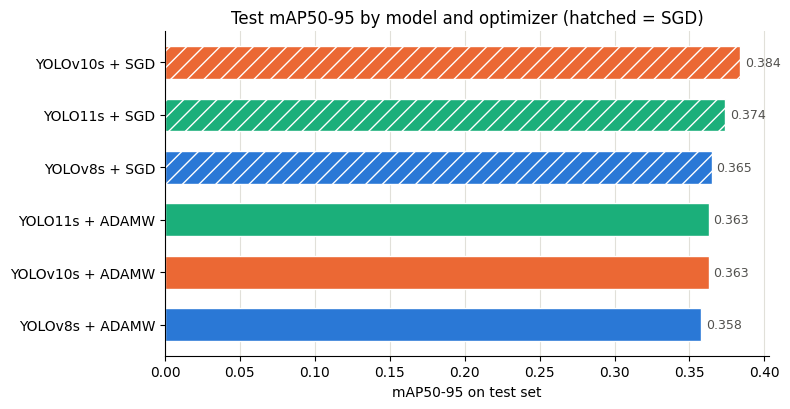

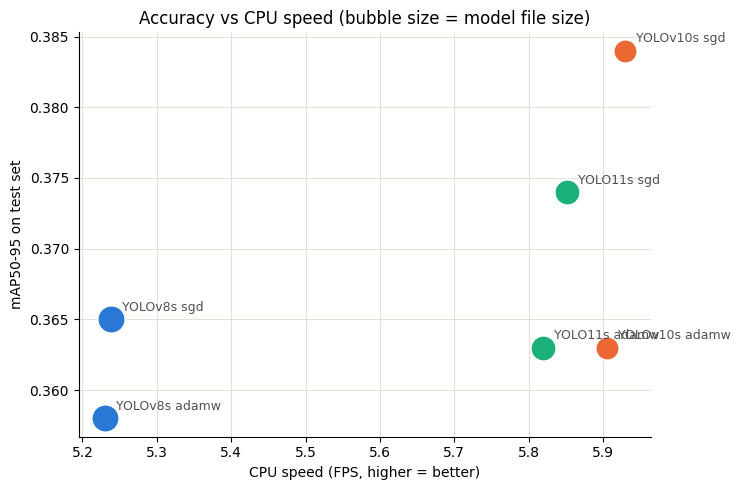

Saved: test_results.csv, test_per_class_AP50.csv, chart_map.png, chart_speed.png
Confusion matrices / PR curves: /kaggle/working/runs/test_eval/<run>/


In [11]:
# ============================================================
# TEST-SET EVALUATION of all runs: mAP, P, R, IoU, FPS, size
# Paste this whole cell at the END of your training notebook and run it once.
# Needs: /kaggle/working/runs/<run>/weights/best.pt and /kaggle/working/road-damage
# ============================================================
import gc
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO
 
RUNS = Path('/kaggle/working/runs')
DATA_DIR = Path('/kaggle/working/road-damage')
DATA_YAML = str(DATA_DIR / 'data.yaml')
LBL_DIR = DATA_DIR / 'test' / 'labels'
TEST_IMGS = sorted((DATA_DIR / 'test' / 'images').glob('*'))
RUN_NAMES = ['v8s_adamw', 'v8s_sgd', 'v10s_adamw', 'v10s_sgd', 'v11s_adamw', 'v11s_sgd']
CONF = 0.25          # confidence threshold used for IoU + deployment-style speed test
N_CPU_IMGS = 100     # images used for the CPU speed test
 
# ---------- helpers (plain numpy, no extra dependencies) ----------
def xyxy_iou(a, b):
    """IoU between every box in a (N,4) and b (M,4) -> (N,M)."""
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)
 
def load_gt(img_path, w, h):
    """Ground-truth boxes in pixels. Polygon rows are converted to their bounding box."""
    f = LBL_DIR / (img_path.stem + '.txt')
    boxes, cls = [], []
    if f.exists():
        for line in f.read_text().splitlines():
            p = line.split()
            if len(p) < 5:
                continue
            v = np.array(p[1:], dtype=float)
            if len(v) == 4:
                xc, yc, bw, bh = v
                x1, y1, x2, y2 = xc - bw / 2, yc - bh / 2, xc + bw / 2, yc + bh / 2
            else:
                xs, ys = v[0::2], v[1::2]
                x1, y1, x2, y2 = xs.min(), ys.min(), xs.max(), ys.max()
            boxes.append([x1 * w, y1 * h, x2 * w, y2 * h]); cls.append(int(float(p[0])))
    return np.array(boxes).reshape(-1, 4), np.array(cls)
 
def match_ious(pb, pc, pconf, gb, gc, thr=0.5):
    """Greedy class-aware matching, highest confidence first. Returns IoUs of matched pairs."""
    order = np.argsort(-pconf)
    pb, pc = pb[order], pc[order]
    ious = xyxy_iou(pb, gb)
    used, matched = set(), []
    for i in range(len(pb)):
        best_j, best = -1, thr
        for j in range(len(gb)):
            if j in used or gc[j] != pc[i]:
                continue
            if ious[i, j] >= best:
                best, best_j = ious[i, j], j
        if best_j >= 0:
            used.add(best_j); matched.append(best)
    return matched
 
def predict_and_score(model, imgs, device):
    """Runs the model on every test image: collects matched IoUs and timings (ms)."""
    matched_all, pre, inf, post = [], [], [], []
    for p in imgs:  # one image at a time (real-time style, batch = 1)
        r = model.predict(str(p), imgsz=640, conf=CONF, device=device, verbose=False)[0]
        h, w = r.orig_shape
        gb, gc = load_gt(Path(p), w, h)
        pb = r.boxes.xyxy.cpu().numpy(); pc = r.boxes.cls.cpu().numpy().astype(int)
        pconf = r.boxes.conf.cpu().numpy()
        matched_all += match_ious(pb, pc, pconf, gb, gc)
        pre.append(r.speed['preprocess']); inf.append(r.speed['inference']); post.append(r.speed['postprocess'])
    k = 10  # drop the first images (GPU warm-up)
    return (float(np.mean(matched_all)) if matched_all else float('nan'),
            float(np.mean(pre[k:])), float(np.mean(inf[k:])), float(np.mean(post[k:])))
 
def cpu_fps(model, imgs):
    tot = []
    for p in imgs:
        r = model.predict(str(p), imgsz=640, conf=CONF, device='cpu', verbose=False)[0]
        tot.append(r.speed['preprocess'] + r.speed['inference'] + r.speed['postprocess'])
    return 1000.0 / float(np.mean(tot[5:]))
 
# ---------- main loop ----------
rows, per_class = [], {}
for name in RUN_NAMES:
    wpath = RUNS / name / 'weights' / 'best.pt'
    if not wpath.exists():
        print(f'[skip] {name}: no best.pt'); continue
    epochs_done = len(pd.read_csv(RUNS / name / 'results.csv'))
    if epochs_done < 20:
        print(f'[WARNING] {name} only trained {epochs_done} epochs - retrain it before trusting these numbers')
    print(f'=== {name} ===')
 
    gc.collect(); torch.cuda.empty_cache()   # free GPU memory left over from training
    _m = YOLO(str(wpath))
    n_params = sum(p.numel() for p in _m.model.parameters()) / 1e6
    try:
        from ultralytics.utils.torch_utils import get_flops
        gflops = get_flops(_m.model, imgsz=640)
    except Exception as e:
        gflops = None
        print('  (could not compute GFLOPs:', e, ')')
    del _m
 
    m = YOLO(str(wpath)).val(data=DATA_YAML, split='test', imgsz=640, batch=16, conf=0.001,
                             plots=True, project=str(RUNS / 'test_eval'), name=name,
                             exist_ok=True, verbose=False, device=0)
    per_class[name] = {m.names[c]: float(m.box.ap50[i]) for i, c in enumerate(m.box.ap_class_index)}
 
    miou, pre, inf, post = predict_and_score(YOLO(str(wpath)), TEST_IMGS, device=0)
    cfps = cpu_fps(YOLO(str(wpath)), TEST_IMGS[:N_CPU_IMGS])
 
    rows.append(dict(
        run=name, epochs=epochs_done,
        precision=m.box.mp, recall=m.box.mr, mAP50=m.box.map50, mAP50_95=m.box.map,
        mean_IoU=miou,
        GPU_FPS_model=1000 / inf, GPU_FPS_total=1000 / (pre + inf + post), CPU_FPS=cfps,
        size_MB=wpath.stat().st_size / 1e6, params_M=n_params, GFLOPs=gflops))
 
res = pd.DataFrame(rows).round(3).sort_values('mAP50_95', ascending=False).reset_index(drop=True)
pc = pd.DataFrame(per_class).round(3)
res.to_csv('/kaggle/working/test_results.csv', index=False)
pc.to_csv('/kaggle/working/test_per_class_AP50.csv')
print('\nNOTE: class "edge" has 0 test instances, so it is NOT included in the test means.')
display(res)
display(pc)
 
# ---------- charts ----------
FAMILY_COLOR = {'v8s': '#2a78d6', 'v10s': '#eb6834', 'v11s': '#1baf7a'}   # blue / orange / aqua
LABEL = {'v8s': 'YOLOv8s', 'v10s': 'YOLOv10s', 'v11s': 'YOLO11s'}
def fam(run): return run.split('_')[0]
def opt(run): return run.split('_')[1]
 
# 1) mAP50-95 per run (bars) - hatched = SGD
fig, ax = plt.subplots(figsize=(8, 4.2))
d = res.sort_values('mAP50_95')
for i, (_, r) in enumerate(d.iterrows()):
    ax.barh(i, r.mAP50_95, color=FAMILY_COLOR[fam(r.run)], hatch='//' if opt(r.run) == 'sgd' else None,
            edgecolor='white', height=0.62)
    ax.text(r.mAP50_95 + 0.003, i, f'{r.mAP50_95:.3f}', va='center', fontsize=9, color='#52514e')
ax.set_yticks(range(len(d))); ax.set_yticklabels([f'{LABEL[fam(x)]} + {opt(x).upper()}' for x in d.run])
ax.set_xlabel('mAP50-95 on test set'); ax.set_title('Test mAP50-95 by model and optimizer (hatched = SGD)')
ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='x', color='#e1e0d9', lw=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig('/kaggle/working/chart_map.png', dpi=150); plt.show()
 
# 2) accuracy vs CPU speed (bubble = file size)
fig, ax = plt.subplots(figsize=(7.5, 5))
for _, r in res.iterrows():
    ax.scatter(r.CPU_FPS, r.mAP50_95, s=r.size_MB * 18, color=FAMILY_COLOR[fam(r.run)],
               edgecolor='white', linewidth=1.5, marker='o')
    ax.annotate(f'{LABEL[fam(r.run)]} {opt(r.run)}', (r.CPU_FPS, r.mAP50_95), textcoords='offset points',
                xytext=(8, 6), fontsize=9, color='#52514e')
ax.set_xlabel('CPU speed (FPS, higher = better)'); ax.set_ylabel('mAP50-95 on test set')
ax.set_title('Accuracy vs CPU speed (bubble size = model file size)')
ax.spines[['top', 'right']].set_visible(False); ax.grid(color='#e1e0d9', lw=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig('/kaggle/working/chart_speed.png', dpi=150); plt.show()
 
print('Saved: test_results.csv, test_per_class_AP50.csv, chart_map.png, chart_speed.png')
print('Confusion matrices / PR curves: /kaggle/working/runs/test_eval/<run>/')
 